In [1]:
import pandas as pd
import numpy as np
from haversine import haversine
from sklearn.manifold import MDS
import matplotlib.pyplot as plt

In [2]:
langs = ["BCL", "CBK", "CEB", "ENG", "HIL", "IFK", "ILO", "KAK", "PAG", "PAM", "SPA", "TAO", "TGL", "TSG", "WAR"]

# Source: https://glottolog.org/glottolog/language
lat = [
  13.76,
  7.44,
  8.39,
  53.00,
  10.40,
  16.66,
  15.94,
  16.32,
  15.94,
  14.96,
  40.44,
  22.05,
  14.06,
  5.12,
  11.49,
]

lon = [
  123.40,
  122.19,
  124.37,
  -1.00,
  122.97,
  121.11,
  120.99,
  120.90,
  120.36,
  120.50,
  -1.12,
  121.54,
  121.75,
  118.88,
  125.01,
]

lang_coords_df = pd.DataFrame({
  "code": langs,
  "lat": lat,
  "lon": lon,
})

# compute distance matrix
n = len(lang_coords_df)
dist = np.zeros((n, n))
for i in range(n):
  for j in range(n):
    dist[i,j] = haversine(
      (lang_coords_df.lat[i],lang_coords_df.lon[i]),
      (lang_coords_df.lat[j],lang_coords_df.lon[j])
    )

geo_dist = pd.DataFrame(dist, index=lang_coords_df.code, columns=lang_coords_df.code)

In [ ]:
sigma = 500
S_geo = np.exp(-geo_dist / sigma)
S_geo_df = pd.DataFrame(S_geo, index=lang_coords_df.code, columns=lang_coords_df.code)
S_orth = pd.read_excel("../sim_matrix/matrix.xlsx", index_col=0)

S_geo_df = S_geo_df.loc[S_orth.index, S_orth.columns]

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


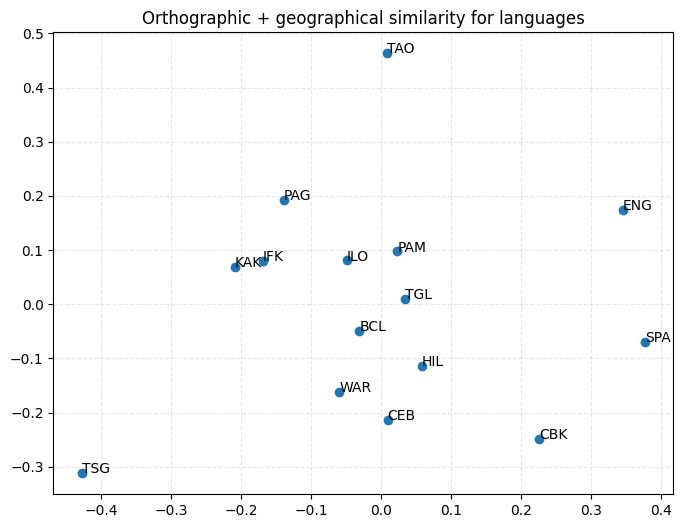

In [11]:
w_orth = 0.8 # weight for orthographic similarity
w_geo = 0.2 # weight for geographical similarity
S_combined = (w_orth*S_orth + w_geo*S_geo_df) / (w_orth + w_geo)

mds = MDS(dissimilarity='precomputed', random_state=0)
coords_2d = mds.fit_transform(1 - S_combined.values)

plt.figure(figsize=(8,6))
plt.scatter(coords_2d[:,0], coords_2d[:,1])
for i, lang in enumerate(S_combined.index):
  plt.text(coords_2d[i,0], coords_2d[i,1], lang)
plt.grid(True, linestyle='--', alpha=0.3)
plt.title("Orthographic + geographical similarity for languages")
plt.savefig("../output/georth_sim.png")
plt.show()